In [1]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-Learn version:", sklearn.__version__)

try:
    import tensorflow as tf
    print("TensorFlow version:", tf.__version__)
except ImportError:
    print("TensorFlow is not installed.")

Pandas version: 3.0.2
NumPy version: 2.3.2
Scikit-Learn version: 1.8.0
TensorFlow is not installed.


In [2]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
Python executable: c:\Users\Chandan sai\AppData\Local\Programs\Python\Python313\python.exe


In [4]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("TensorFlow is working!")

TensorFlow version: 2.21.0
TensorFlow is working!


In [6]:
import pandas as pd

# Create a small demonstration dataset
data = {
    "text": [
        "I love this product",
        "This is amazing",
        "I am very happy",
        "Excellent quality",
        "The product is wonderful",
        "I really enjoyed it",
        "This is fantastic",
        "Very good experience",
        "I am satisfied",
        "Absolutely brilliant",
        "I hate this product",
        "This is terrible",
        "I am very disappointed",
        "Poor quality",
        "The product is awful",
        "I really disliked it",
        "This is horrible",
        "Very bad experience",
        "I am unsatisfied",
        "Absolutely disappointing",
        "The service was excellent",
        "I enjoyed the experience",
        "The quality is great",
        "I would recommend this",
        "The service was awful",
        "I regret buying this",
        "The experience was terrible",
        "I would not recommend this",
        "The product works perfectly",
        "The product stopped working"
    ],
    "sentiment": [
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        1, 1, 1, 1, 0, 0, 0, 0, 1, 0
    ]
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print("Total reviews:", len(df))
print("\nFirst five reviews:")
display(df.head())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

Dataset created successfully!
Total reviews: 30

First five reviews:


,text,sentiment
0,I love this product,1
1,This is amazing,1
2,I am very happy,1
3,Excellent quality,1
4,The product is wonderful,1



Sentiment distribution:
sentiment
1    15
0    15
Name: count, dtype: int64


In [12]:
from sklearn.model_selection import train_test_split

# Separate input text and target labels
X = df["text"]
y = df["sentiment"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training data prepared successfully!")

Training samples: 24
Testing samples: 6
Training data prepared successfully!


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=100)

# Learn vocabulary from training reviews
X_train_tfidf = tfidf.fit_transform(X_train)

# Convert testing reviews using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

# Convert sparse matrices into arrays for TensorFlow
X_train_tfidf = X_train_tfidf.toarray()
X_test_tfidf = X_test_tfidf.toarray()

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)
print("Number of TF-IDF features:", len(tfidf.get_feature_names_out()))

print("\nFirst five TF-IDF features:")
print(tfidf.get_feature_names_out()[:5])

Training feature shape: (24, 37)
Testing feature shape: (6, 37)
Number of TF-IDF features: 37

First five TF-IDF features:
['absolutely' 'am' 'amazing' 'awful' 'bad']


In [15]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization

model = Sequential([
    Input(shape=(X_train_tfidf.shape[1],)),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),

    Dense(32, activation="relu"),
    BatchNormalization(),
    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,929 (19.25 KB)

 Trainable params: 4,737 (18.50 KB)

 Non-trainable params: 192 (768.00 B)

In [16]:
from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss does not improve
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

print("Early Stopping callback created successfully!")

Early Stopping callback created successfully!


In [17]:
history = model.fit(
    X_train_tfidf,
    y_train,
    epochs=50,
    batch_size=4,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

print("\nModel training completed!")

Epoch 1/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 85ms/step - accuracy: 0.5789 - loss: 0.6848 - val_accuracy: 0.6000 - val_loss: 0.6868
Epoch 2/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5263 - loss: 0.7880 - val_accuracy: 0.4000 - val_loss: 0.6905
Epoch 3/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6842 - loss: 0.6165 - val_accuracy: 0.2000 - val_loss: 0.6941
Epoch 4/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6316 - loss: 0.5874 - val_accuracy: 0.4000 - val_loss: 0.6961
Epoch 5/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7368 - loss: 0.4771 - val_accuracy: 0.6000 - val_loss: 0.7007
Epoch 6/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6316 - loss: 0.7174 - val_accuracy: 0.6000 - val_loss: 0.7039

Model training completed!


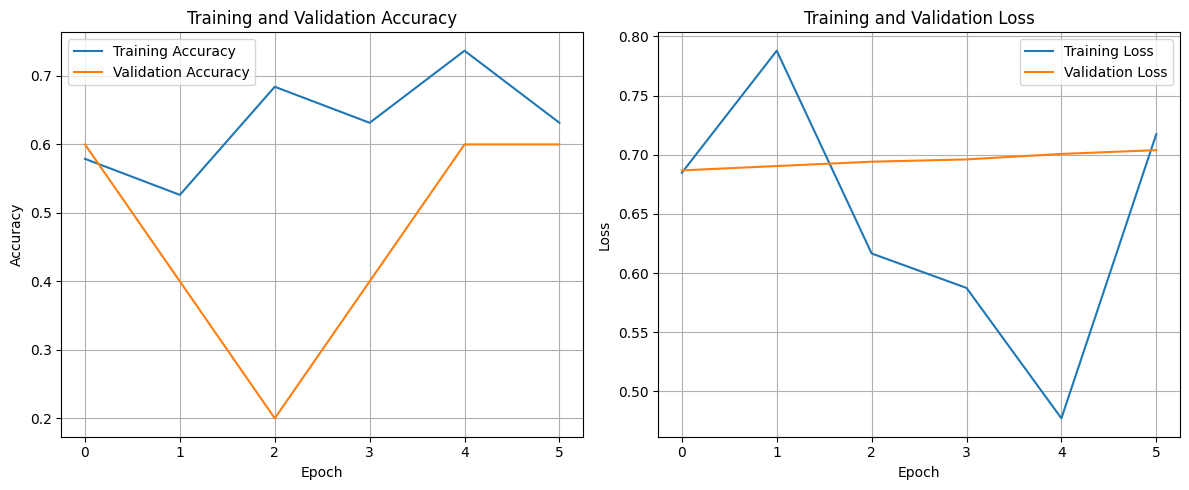

In [18]:
import matplotlib.pyplot as plt

# Create a figure for the training curves
plt.figure(figsize=(12, 5))

# Plot accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [19]:
# Evaluate the model on the held-out test set
test_loss, test_accuracy = model.evaluate(
    X_test_tfidf,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy Percentage: {test_accuracy * 100:.2f}%")

Test Loss: 0.7235
Test Accuracy: 0.5000
Test Accuracy Percentage: 50.00%


In [20]:
# New reviews that were not included in the training dataset
new_reviews = [
    "The product is amazing and I love it",
    "This product is terrible and disappointing",
    "The quality is excellent",
    "I hate this experience"
]

# Convert the new reviews using our trained TF-IDF vectorizer
new_reviews_tfidf = tfidf.transform(new_reviews).toarray()

# Predict the probability of positive sentiment
positive_probabilities = model.predict(new_reviews_tfidf, verbose=0).flatten()

# Display predictions and confidence scores
for review, probability in zip(new_reviews, positive_probabilities):
    sentiment = "Positive" if probability >= 0.5 else "Negative"
    confidence = probability if probability >= 0.5 else 1 - probability

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print(f"Positive probability: {probability:.4f}")
    print(f"Classification confidence: {confidence:.2%}")
    print("-" * 50)

Review: The product is amazing and I love it
Predicted sentiment: Positive
Positive probability: 0.5222
Classification confidence: 52.22%
--------------------------------------------------
Review: This product is terrible and disappointing
Predicted sentiment: Positive
Positive probability: 0.5393
Classification confidence: 53.93%
--------------------------------------------------
Review: The quality is excellent
Predicted sentiment: Positive
Positive probability: 0.5386
Classification confidence: 53.86%
--------------------------------------------------
Review: I hate this experience
Predicted sentiment: Positive
Positive probability: 0.5419
Classification confidence: 54.19%
--------------------------------------------------
